<a href="https://colab.research.google.com/github/Guliko24/CE880_Case_Study/blob/main/CE880_Case_study_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
uploaded = files.upload()

Saving data_PostNatal.xlsx to data_PostNatal.xlsx


In [3]:
import pandas as pd
data= "/content/data_PostNatal.xlsx"
df=pd.read_excel(data)
df.head()

,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling of guilt,Problems of bonding with baby,Suicide attempt,Feeling anxious
0,35-40,Yes,Yes,Two or more days a week,Yes,Yes,No,Yes,Yes,Yes
1,40-45,Yes,No,No,Yes,Yes,Yes,Yes,No,No
2,35-40,Yes,No,Yes,Yes,Yes,No,Sometimes,No,Yes
3,35-40,Yes,Yes,Yes,Yes,No,Maybe,No,No,Yes
4,40-45,Yes,No,Two or more days a week,Yes,No,No,Yes,No,Yes


Let's do some exloratory data analysis

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# from pd.tools import plotting
from scipy import stats
plt.style.use("ggplot")
import warnings
warnings.filterwarnings("ignore")
from scipy import stats



## **Basic EDA and statistical analysis**

In [5]:

df.info(verbose=True)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   Age                                        1503 non-null   object
 1   Feeling sad or Tearful                     1503 non-null   object
 2   Irritable towards baby & partner           1497 non-null   object
 3   Trouble sleeping at night                  1503 non-null   object
 4   Problems concentrating or making decision  1491 non-null   object
 5   Overeating or loss of appetite             1503 non-null   object
 6   Feeling of guilt                           1494 non-null   object
 7   Problems of bonding with baby              1503 non-null   object
 8   Suicide attempt                            1503 non-null   object
 9   Feeling anxious                            1503 non-null   object
dtypes: object(10)
memory usage: 117.5+ K

In [6]:
df.describe()


,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling of guilt,Problems of bonding with baby,Suicide attempt,Feeling anxious
count,1503,1503,1497,1503,1491,1503,1494,1503,1503,1503
unique,5,3,3,3,3,3,3,3,3,2
top,40-45,Yes,Yes,Two or more days a week,No,No,No,No,No,Yes
freq,364,536,555,640,583,841,624,557,709,980


In [7]:
df.isna().sum()

Age                                           0
Feeling sad or Tearful                        0
Irritable towards baby & partner              6
Trouble sleeping at night                     0
Problems concentrating or making decision    12
Overeating or loss of appetite                0
Feeling of guilt                              9
Problems of bonding with baby                 0
Suicide attempt                               0
Feeling anxious                               0
dtype: int64

In [28]:
#in order to fill this NaNs, we need to see the data distribution, but I could not plot categorical data.
#Let's replace NaN values with modes as these are non-numerical/categorical values
df_copy=df.copy()

df_copy['Irritable towards baby & partner'].fillna(df_copy['Irritable towards baby & partner'].mode()[0], inplace = True)
df_copy['Problems concentrating or making decision'].fillna(df_copy['Problems concentrating or making decision'].mode()[0], inplace = True)
df_copy['Feeling of guilt'].fillna(df_copy['Feeling of guilt'].mode()[0], inplace = True)
df_copy.isna().sum()

Age                                          0
Feeling sad or Tearful                       0
Irritable towards baby & partner             0
Trouble sleeping at night                    0
Problems concentrating or making decision    0
Overeating or loss of appetite               0
Feeling of guilt                             0
Problems of bonding with baby                0
Suicide attempt                              0
Feeling anxious                              0
dtype: int64

<Axes: xlabel='Feeling anxious', ylabel='Count'>

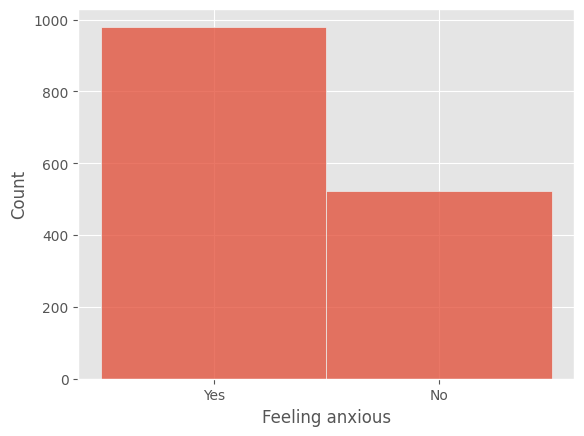

In [9]:
sns.histplot(df["Feeling anxious"])

The above plot shows that the outcome is not normally distributed and there is over-repesentation of the 'Yes'. Some undersampling or oversampling will be needed when trainig models.


**Data Visualization**


In [10]:
# Let's check the distribution/representation of the target "Feeling anxious"

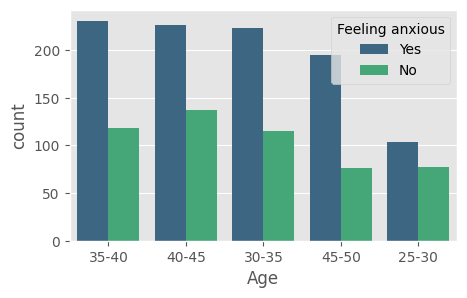

In [11]:

import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'df_copy' is your DataFrame and it's already defined
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed

sns.countplot(x='Age', hue='Feeling anxious', data=df_copy, palette='viridis')

plt.show()# Age vs Feeling Anxious



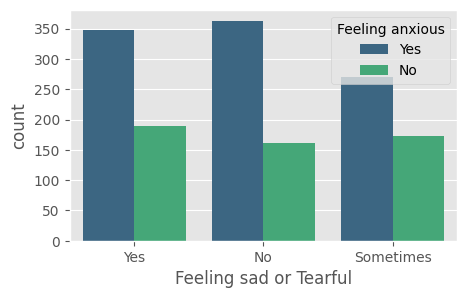

In [12]:

# Assuming 'df_copy' is your DataFrame and it's already defined
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed

sns.countplot(x='Feeling sad or Tearful', hue='Feeling anxious', data=df_copy, palette='viridis')

plt.show()


There seems no correlation of feeling sad/tearful with Feeling anxious as both Yes and Nos and Sometimes lead to double the outcome of Yes/Feeling anxious


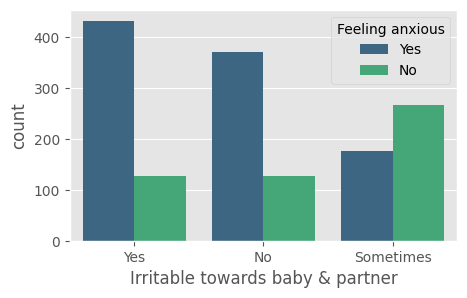

In [13]:
# Irritable towards baby & partner vs Feeling anxious
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed

sns.countplot(x='Irritable towards baby & partner', hue='Feeling anxious', data=df_copy, palette='viridis')

plt.show()



This particular feature does not seem to contribute to the particular outcome.

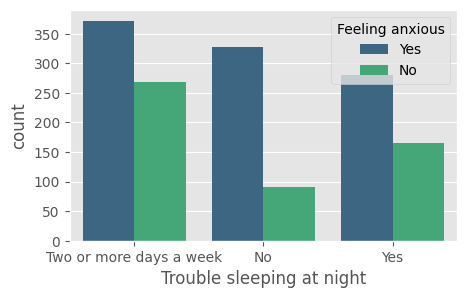

In [14]:
#Trouble sleeping at night vs Feeling anxious
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed
sns.countplot(x='Trouble sleeping at night', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()

There seems to be some correlation of sleep and feeling anxious

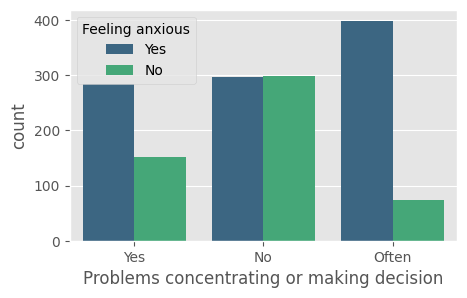

In [15]:
#Problems concentrating or making decision
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed
sns.countplot(x='Problems concentrating or making decision', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()


The above plot shows that the outcome is not normally distributed and there is over-repesentation of the 'Yes'. Some undersampling or oversampling will be needed.


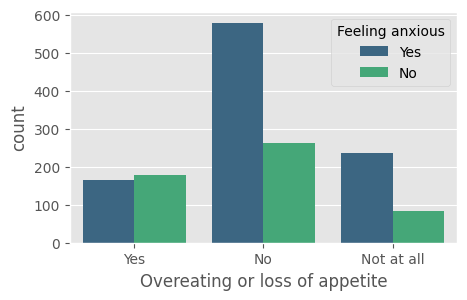

In [16]:
#Overeating or loss of appetite
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed
sns.countplot(x='Overeating or loss of appetite', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()

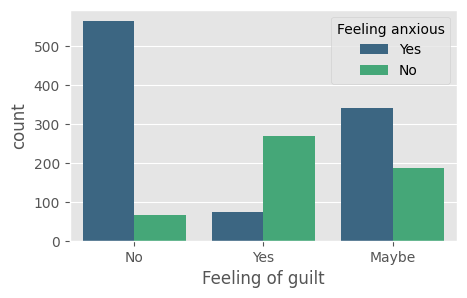

In [17]:
#Feeling of guilt                              9
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed
sns.countplot(x='Feeling of guilt', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()

This is a very "strange"plot when the feature is in negative correlation with an outcome

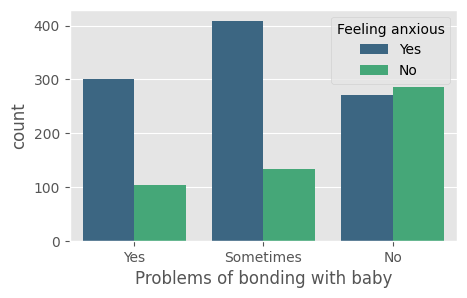

In [18]:
#Problems of bonding with baby
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed
sns.countplot(x='Problems of bonding with baby', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()

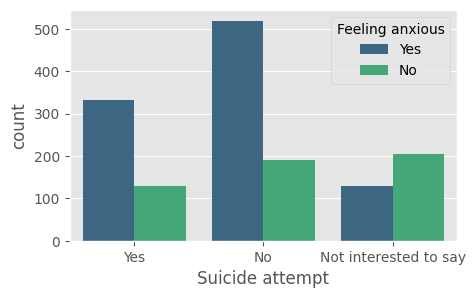

In [19]:
#Suicide attempt
plt.figure(figsize=(5, 3))  # Adjust the width and height as needed
sns.countplot(x='Suicide attempt', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()

In [20]:
#it is worth trying Shapley coeff here to see which features are the most contributing to the outcome

# **Data Preprocessing**

-I am not dropping any feature at this moment
-All the NaNs have been replaced with modes for that feature.



In [34]:
#let's separate the data and labels

X = df_copy.loc[:, df.columns != 'Feeling anxious']
Y = df_copy.loc[:, 'Feeling anxious']
print(X.shape, Y.shape)

(1503, 9) (1503,)


In [36]:

# One Hot Encoding of all the columns in X
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define the column indices that you want to transform - in this case, columns 0 to 7
columns_to_encode = list(range(9))

ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), columns_to_encode)], remainder='passthrough')

# Apply the ColumnTransformer to the DataFrame
X_encoded = ct.fit_transform(X)

# If you want to convert the output to a DataFrame, you can do the following:
# The below code assumes that `X` is a pandas DataFrame, and the `ct` transformer returns a NumPy array
column_names = ct.get_feature_names_out()  # Get the new column names after transformation
X_encoded_df = pd.DataFrame(X_encoded, columns=column_names)

In [40]:
#X_encoded_df.head()


In [59]:
#One hot encoding of Y

# Assuming Y is your pandas Series
Y_array = Y.values.reshape(-1, 1)  # Convert to NumPy array and reshape

# Initialize the OneHotEncoder
encoder = OneHotEncoder(sparse=False)

# Fit and transform the reshaped array
Y_encoded = encoder.fit_transform(Y_array)
Y_encoded.shape


(1503, 2)

# **Training Models**

In [60]:
#let's split the data to Train and Test
from sklearn.model_selection import train_test_split

# Assume X and Y are your features and labels, respectively.
# X_encoded = ... (My data features)
# Y_encoded= ... (My data labels)

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X_encoded, Y_encoded, test_size=0.2, random_state=42)
#convert both Y_train and Y_test back to single column labels or model gives an error
Y_train=Y_train.argmax(axis=1)
Y_test=Y_test.argmax(axis=1)

## Logistic Regression

In [61]:
#Let's start with a simple of model of Logistic Regression (LR) without any over or undersampling
from sklearn.linear_model import LogisticRegression
logistic_regression_classifier = LogisticRegression(max_iter = 1000, random_state=0)
logistic_regression_classifier.fit(X_train, Y_train)
Y_pred = logistic_regression_classifier.predict(X_test)


#evaluate  the model with accuracy scores
from sklearn.metrics import accuracy_score, classification_report


# Calculate the accuracy
accuracy = accuracy_score(Y_test, Y_pred)
print(f"Accuracy: {accuracy}")

# Print a detailed classification report
print(classification_report(Y_test, Y_pred))


Accuracy: 0.8239202657807309
              precision    recall  f1-score   support

           0       0.71      0.76      0.73        95
           1       0.88      0.85      0.87       206

    accuracy                           0.82       301
   macro avg       0.80      0.81      0.80       301
weighted avg       0.83      0.82      0.83       301



In [55]:
#Let's try undersampling and then LR to compare
from imblearn.under_sampling import RandomUnderSampler


# Apply Random Under-Sampling
rus = RandomUnderSampler(random_state=42)
X_train_resampled, Y_train_resampled = rus.fit_resample(X_train, Y_train)

# Now X_train_resampled and Y_train_resampled have balanced classes
from sklearn.linear_model import LogisticRegression
logistic_regression_classifier = LogisticRegression(max_iter = 1000, random_state=0)
logistic_regression_classifier.fit(X_train_resampled, Y_train_resampled)
Y_pred = logistic_regression_classifier.predict(X_test)


#evaluate  the model with accuracy scores
from sklearn.metrics import accuracy_score, classification_report


# Calculate the accuracy
accuracy = accuracy_score(Y_test, Y_pred)
print(f"Accuracy: {accuracy}")

# Print a detailed classification report
print(classification_report(Y_test, Y_pred))




Accuracy: 0.8073089700996677
              precision    recall  f1-score   support

           0       0.65      0.83      0.73        95
           1       0.91      0.80      0.85       206

    accuracy                           0.81       301
   macro avg       0.78      0.81      0.79       301
weighted avg       0.83      0.81      0.81       301



Looks like undersampling improved the precision for "Yes"
I will not attempt over-sampling.



In [70]:
#Let's try doing stratified K-fold cross validation with the LR instead
from sklearn.model_selection import StratifiedKFold, cross_validate


# Assuming X and Y are your features and labels, respectively
Y=np.argmax(Y_encoded, axis=1)
# Initialize a logistic regression model
model = LogisticRegression(max_iter=1000, solver='lbfgs', random_state=42)

# Initialize the stratified K-fold object
stratified_k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform cross-validation
scoring_metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
cv_results = cross_validate(model, X_encoded, Y, cv=stratified_k_fold, scoring=scoring_metrics)

# Print the accuracy for each fold
print(f'Accuracy for each fold: {scores}')

# Print the results for each metric
for metric in scoring_metrics:
    scores = cv_results[f'test_{metric}']
    print(f'{metric.capitalize()} for each fold: {scores}')
    print(f'Mean {metric}: {np.mean(scores)}\n')

Accuracy for each fold: {'fit_time': array([0.03536749, 0.01961875, 0.02079558, 0.03443289, 0.06173229]), 'score_time': array([0.01479149, 0.01178551, 0.01119852, 0.01658487, 0.01178384]), 'test_accuracy': array([0.83056478, 0.81727575, 0.81063123, 0.8       , 0.81666667]), 'test_precision_macro': array([0.82180095, 0.80215955, 0.79670273, 0.78056173, 0.79842281]), 'test_recall_macro': array([0.79693878, 0.78894558, 0.77721088, 0.7724686 , 0.79425039]), 'test_f1_macro': array([0.80657721, 0.79460553, 0.78495958, 0.77610826, 0.79623341])}
Accuracy for each fold: [0.83056478 0.81727575 0.81063123 0.8        0.81666667]
Mean accuracy: 0.8150276854928018

Precision_macro for each fold: [0.82180095 0.80215955 0.79670273 0.78056173 0.79842281]
Mean precision_macro: 0.7999295525304875

Recall_macro for each fold: [0.79693878 0.78894558 0.77721088 0.7724686  0.79425039]
Mean recall_macro: 0.7859628466771325

F1_macro for each fold: [0.80657721 0.79460553 0.78495958 0.77610826 0.79623341]
Mean 